In [ ]:
import matplotlib.pyplot as plt
import os
import sys
import time
import socket
import threading
import csv
import numpy as np

from datetime import datetime
from ctypes import c_int16, c_int32, byref, c_char_p, c_float

from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok


# ---------------------------------------------------------------------
# Local component imports
# ---------------------------------------------------------------------

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp


# ---------------------------------------------------------------------
# Hardware setup
# ---------------------------------------------------------------------

laser = comp.Toptica_Laser()

powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR',
    num_power_readings=100,
    bs_factor=1,
    wavelength=950
)


# ---------------------------------------------------------------------
# Utility functions
# ---------------------------------------------------------------------

def make_data_folder(base_directory='D:/Data'):
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')

    folder_path = os.path.join(
        base_directory,
        year,
        year_month,
        year_month_day
    )

    os.makedirs(folder_path, exist_ok=True)
    return folder_path


def format_for_filename(x):
    """Keep decimal points in filenames but remove spaces."""
    return str(x).strip().replace(" ", "")


def save_arrays(
        voltage_array,
        time_array,
        commanded_power_mW,
        measured_power_uW,
        iteration,
        gain_value,
        base_directory='D:/Data',
        save_time_once=True
):
    folder_path = make_data_folder(base_directory)
    timestamp = datetime.now().strftime('%H%M%S')

    laserp_str = f"{commanded_power_mW:.3g}"
    measp_str = f"{measured_power_uW:.3g}"
    gain_str = format_for_filename(gain_value)

    suffix = (
        f"laserp_{laserp_str}_mW"
        f"_measp_{measp_str}_uW"
        f"_iter{iteration:03d}"
        f"_gain_{gain_str}"
    )

    voltage_filename = f"pbec_{timestamp}_{suffix}_Voltage.txt"
    voltage_path = os.path.join(folder_path, voltage_filename)

    np.savetxt(voltage_path, voltage_array, fmt='%0.4f')

    time_path = None

    if save_time_once:
        time_filename = "pbec_Time.txt"
        time_path = os.path.join(folder_path, time_filename)

        if not os.path.exists(time_path):
            np.savetxt(time_path, time_array, fmt='%0.4f')

    return voltage_path, time_path

# ---------------------------------------------------------------------
# PicoScope acquisition
# ---------------------------------------------------------------------

def get_picoscope_data(
        channels=[0],
        analogue_offset=0,
        trig=0,
        trigsource=0,
        trigthresh=64,
        trigdir=2,
        trigdelay=0,
        trigms=1000,
        preTriggerSamples=2500,
        postTriggerSamples=2500,
        timebase=8,
        live_plot=False
):
    status = {}
    chandle = c_int16()
    serial = c_char_p()

    status["openunit"] = ps.ps6000OpenUnit(byref(chandle), serial)
    assert status["openunit"] == 0, (
        f"Failed to open PicoScope 6407, "
        f"error code: {status['openunit']}"
    )

    try:
        channel_mapping = {
            0: 'PS6000_CHANNEL_A',
            1: 'PS6000_CHANNEL_B',
            2: 'PS6000_CHANNEL_C',
            3: 'PS6000_CHANNEL_D'
        }

        buffers = {}
        chARange = ps.PS6000_RANGE['PS6000_100MV']

        maxSamples = preTriggerSamples + postTriggerSamples

        for ch in channels:
            if ch not in channel_mapping:
                raise ValueError("Invalid channel. Use 0, 1, 2, or 3.")

            channel = ps.PS6000_CHANNEL[channel_mapping[ch]]
            enabled = 1
            coupling_type = ps.PS6000_COUPLING['PS6000_DC_50R']
            bandwidth = ps.PS6000_BANDWIDTH_LIMITER['PS6000_BW_FULL']

            status[f"set_channel_{ch}"] = ps.ps6000SetChannel(
                chandle,
                channel,
                enabled,
                coupling_type,
                chARange,
                analogue_offset,
                bandwidth
            )
            assert_pico_ok(status[f"set_channel_{ch}"])

            buffers[ch] = {
                'max': (c_int16 * maxSamples)(),
                'min': (c_int16 * maxSamples)()
            }

            status[f"setDataBuffers_{ch}"] = ps.ps6000SetDataBuffers(
                chandle,
                channel,
                byref(buffers[ch]['max']),
                byref(buffers[ch]['min']),
                maxSamples,
                0
            )
            assert_pico_ok(status[f"setDataBuffers_{ch}"])

        status["trigger"] = ps.ps6000SetSimpleTrigger(
            chandle,
            trig,
            trigsource,
            trigthresh,
            trigdir,
            trigdelay,
            trigms
        )
        assert_pico_ok(status["trigger"])

        timeIntervalns = c_float()
        returnedMaxSamples = c_int32()

        status["getTimebase2"] = ps.ps6000GetTimebase2(
            chandle,
            timebase,
            maxSamples,
            byref(timeIntervalns),
            1,
            byref(returnedMaxSamples),
            0
        )
        assert_pico_ok(status["getTimebase2"])

        status["runBlock"] = ps.ps6000RunBlock(
            chandle,
            preTriggerSamples,
            postTriggerSamples,
            timebase,
            0,
            None,
            0,
            None,
            None
        )
        assert_pico_ok(status["runBlock"])

        ready = c_int16(0)

        while ready.value == 0:
            status["isReady"] = ps.ps6000IsReady(chandle, byref(ready))

        overflow = c_int16()
        cmaxSamples = c_int32(maxSamples)

        status["getValues"] = ps.ps6000GetValues(
            chandle,
            0,
            byref(cmaxSamples),
            1,
            0,
            0,
            byref(overflow)
        )
        assert_pico_ok(status["getValues"])

        maxADC = c_int16(32512)

        channel_data = {}

        for ch in channels:
            adc2mV_buffer = adc2mV(
                buffers[ch]['max'],
                chARange,
                maxADC
            )
            channel_data[ch] = np.array(adc2mV_buffer)

        time_array = np.linspace(
            0,
            (cmaxSamples.value - 1) * timeIntervalns.value,
            cmaxSamples.value
        )

        if live_plot:
            plt.figure(figsize=(6, 4))

            for ch in channels:
                plt.plot(
                    time_array,
                    channel_data[ch],
                    label=f"Channel {channel_mapping[ch]}"
                )

            plt.xlabel('Time (ns)')
            plt.ylabel('Voltage (mV)')
            plt.title("PicoScope capture")
            plt.legend()
            plt.grid()
            plt.show()

        status["stop"] = ps.ps6000Stop(chandle)
        assert_pico_ok(status["stop"])

    finally:
        ps.ps6000CloseUnit(chandle)

    return channel_data, time_array


# ---------------------------------------------------------------------
# Power meter thread
# ---------------------------------------------------------------------

def power_meter_worker(
        powermeter,
        stop_event,
        measured_power,
        measured_time,
        dt=0.1
):
    t0 = time.time()

    while not stop_event.is_set():
        try:
            reading_uW = 1e6 * powermeter.take_power_reading()
            measured_power.append(reading_uW)
            measured_time.append(time.time() - t0)

        except Exception:
            pass

        time.sleep(dt)


def acquire_scope_and_power(
        powermeter,
        scope_kwargs,
        power_meter_dt=0.1
):
    measured_power = []
    measured_time = []

    t0 = time.time()

    # One immediate reading before scope acquisition.
    # Failures are ignored to avoid cluttering the terminal.
    try:
        first_reading_uW = 1e6 * powermeter.take_power_reading()
        measured_power.append(first_reading_uW)
        measured_time.append(time.time() - t0)
    except Exception:
        pass

    stop_event = threading.Event()

    thread = threading.Thread(
        target=power_meter_worker,
        args=(
            powermeter,
            stop_event,
            measured_power,
            measured_time,
            power_meter_dt
        ),
        daemon=True
    )

    thread.start()

    try:
        channel_data, time_array = get_picoscope_data(**scope_kwargs)
    finally:
        stop_event.set()
        thread.join(timeout=2)

    # One final reading after scope acquisition.
    # Failures are ignored to avoid cluttering the terminal.
    try:
        final_reading_uW = 1e6 * powermeter.take_power_reading()
        measured_power.append(final_reading_uW)
        measured_time.append(time.time() - t0)
    except Exception:
        pass

    measured_power = np.array(measured_power)
    measured_time = np.array(measured_time)

    if len(measured_power) == 0:
        mean_power_uW = np.nan
        std_power_uW = np.nan
    else:
        mean_power_uW = np.mean(measured_power)
        std_power_uW = np.std(measured_power)

    return (
        channel_data,
        time_array,
        measured_time,
        measured_power,
        mean_power_uW,
        std_power_uW
    )


# ---------------------------------------------------------------------
# Full power scan
# ---------------------------------------------------------------------

def run_power_scan(
        power_list,
        laser,
        powermeter,
        n_iterations=1,
        base_directory='D:/Data',
        settle_time_s=1.0,
        power_meter_dt=0.1,
        channel_to_save=0,
        voltage_threshold_mV=80,
        initial_gain_value="NA",
        scope_kwargs=None
):
    """
    Power scan logic:
      1. Set laser power.
      2. Acquire scope trace and simultaneous power reading.
      3. Check saturation BEFORE saving.
      4. If saturated, ask for a new gain and reacquire the same iteration.
      5. Save only when the trace is not saturated.

    Saturated traces are deliberately discarded.
    """
    if scope_kwargs is None:
        scope_kwargs = dict(
            channels=[0],
            analogue_offset=0,
            trig=0,
            trigsource=0,
            trigthresh=64,
            trigdir=2,
            trigdelay=0,
            trigms=1000,
            preTriggerSamples=2500,
            postTriggerSamples=2500,
            timebase=8,
            live_plot=True
        )

    iteration = 0
    current_gain = initial_gain_value

    for power_W in power_list:
        commanded_power_mW = power_W * 1e3

        print("")
        print(f"Setting laser to {commanded_power_mW:.4f} mW")

        laser.set(power_W)
        time.sleep(settle_time_s)

        for _ in range(n_iterations):

            while True:
                print("")
                print(f"Iteration {iteration}")
                print(f"Current gain = {current_gain}")

                (
                    channel_data,
                    time_array,
                    power_time,
                    power_trace,
                    mean_power_uW,
                    std_power_uW
                ) = acquire_scope_and_power(
                    powermeter=powermeter,
                    scope_kwargs=scope_kwargs,
                    power_meter_dt=power_meter_dt
                )

                voltage_array = channel_data[channel_to_save]
                max_abs_voltage = np.max(np.abs(voltage_array))

                # ------------------------------------------------------
                # Check saturation BEFORE saving.
                # Saturated traces are discarded and reacquired.
                # ------------------------------------------------------
                if max_abs_voltage > voltage_threshold_mV:
                    print("")
                    print(
                        f"Signal exceeded ±{voltage_threshold_mV} mV "
                        f"(max |V| = {max_abs_voltage:.2f} mV)."
                    )
                    print("Please change gain.")

                    new_gain = input(
                        "Enter new gain value, then press Enter to reacquire this trace: "
                    )

                    if new_gain.strip() != "":
                        current_gain = new_gain.strip()

                    print(f"Reacquiring iteration {iteration} with gain = {current_gain}")
                    continue

                # ------------------------------------------------------
                # Save only if the trace is not saturated.
                # ------------------------------------------------------
                print(f"Measured power during trace: {mean_power_uW:.3g} uW")
                print(f"Max |V| = {max_abs_voltage:.2f} mV")

                voltage_path, time_path = save_arrays(
                    voltage_array=voltage_array,
                    time_array=time_array,
                    commanded_power_mW=commanded_power_mW,
                    measured_power_uW=mean_power_uW,
                    iteration=iteration,
                    gain_value=current_gain,
                    base_directory=base_directory,
                    save_time_once=True
                )

                print("Saved voltage:")
                print(voltage_path)

                if time_path is not None:
                    print("Time file:")
                    print(time_path)

                iteration += 1
                break

    print("")
    print("Power scan complete.")



Setting laser to 0.0000 mW

Iteration 0
Current gain = 70


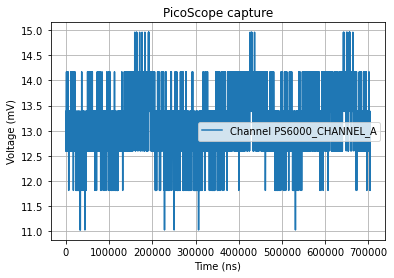

Measured power during trace: 1.24 uW
Max |V| = 14.96 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144452_laserp_0_mW_measp_1.24_uW_iter000_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 1
Current gain = 70


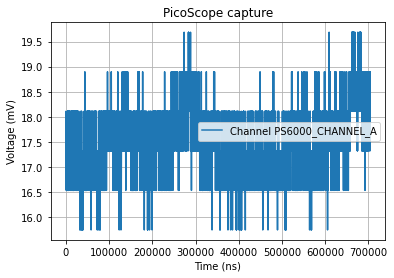

Measured power during trace: 1.35 uW
Max |V| = 19.69 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144503_laserp_0_mW_measp_1.35_uW_iter001_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 2
Current gain = 70


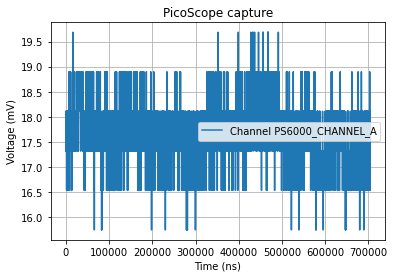

Measured power during trace: 1.36 uW
Max |V| = 19.69 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144513_laserp_0_mW_measp_1.36_uW_iter002_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 21.0000 mW

Iteration 3
Current gain = 70


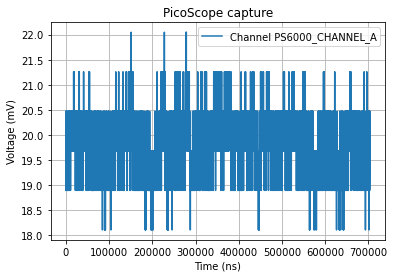

Measured power during trace: 1.36 uW
Max |V| = 22.05 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144526_laserp_21_mW_measp_1.36_uW_iter003_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 4
Current gain = 70


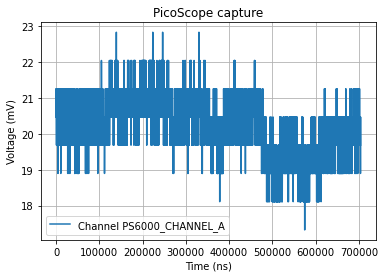

Measured power during trace: 1.35 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144537_laserp_21_mW_measp_1.35_uW_iter004_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 5
Current gain = 70


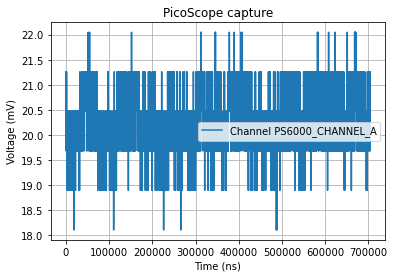

Measured power during trace: 1.37 uW
Max |V| = 22.05 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144548_laserp_21_mW_measp_1.37_uW_iter005_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 21.5000 mW

Iteration 6
Current gain = 70


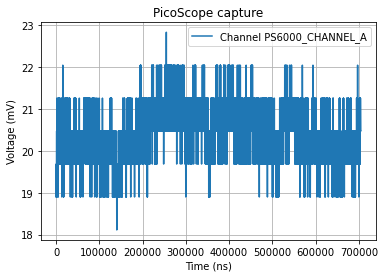

Measured power during trace: 1.37 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144600_laserp_21.5_mW_measp_1.37_uW_iter006_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 7
Current gain = 70


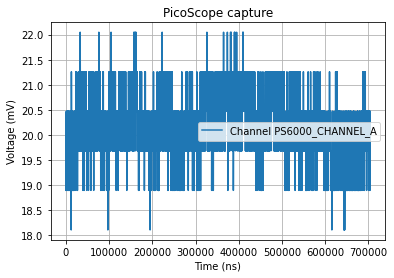

Measured power during trace: 1.36 uW
Max |V| = 22.05 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144610_laserp_21.5_mW_measp_1.36_uW_iter007_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 8
Current gain = 70


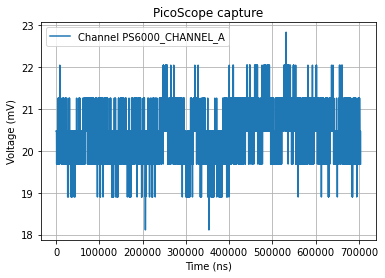

Measured power during trace: 1.36 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144618_laserp_21.5_mW_measp_1.36_uW_iter008_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 22.0000 mW

Iteration 9
Current gain = 70


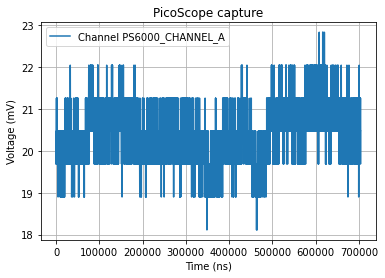

Measured power during trace: 1.37 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144632_laserp_22_mW_measp_1.37_uW_iter009_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 10
Current gain = 70


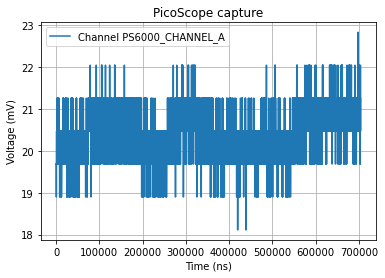

Measured power during trace: 1.36 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144639_laserp_22_mW_measp_1.36_uW_iter010_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 11
Current gain = 70


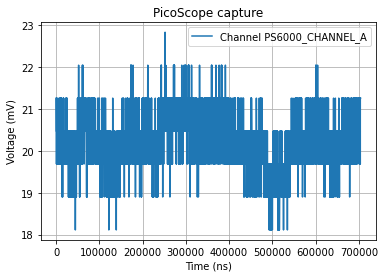

Measured power during trace: 1.36 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144653_laserp_22_mW_measp_1.36_uW_iter011_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 22.5000 mW

Iteration 12
Current gain = 70


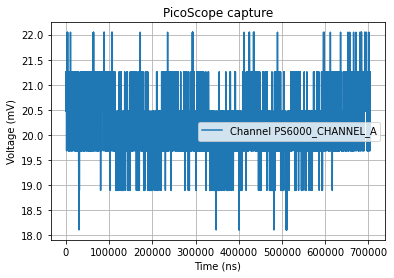

Measured power during trace: 1.36 uW
Max |V| = 22.05 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144705_laserp_22.5_mW_measp_1.36_uW_iter012_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 13
Current gain = 70


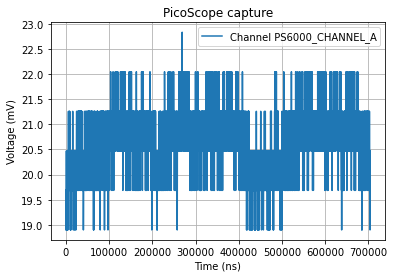

Measured power during trace: 1.36 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144716_laserp_22.5_mW_measp_1.36_uW_iter013_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 14
Current gain = 70


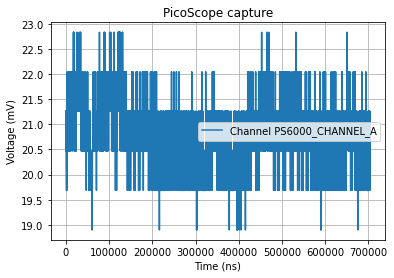

Measured power during trace: 1.37 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144726_laserp_22.5_mW_measp_1.37_uW_iter014_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 23.0000 mW

Iteration 15
Current gain = 70


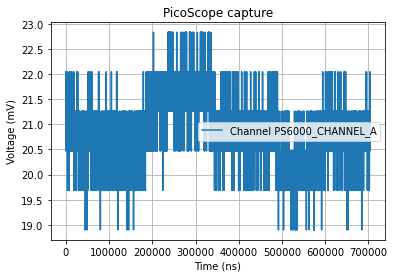

Measured power during trace: 1.37 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144735_laserp_23_mW_measp_1.37_uW_iter015_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 16
Current gain = 70


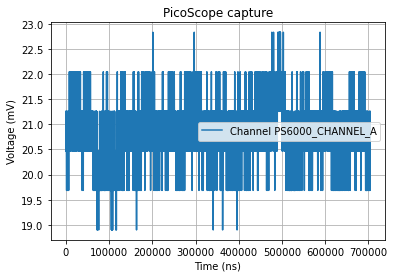

Measured power during trace: 1.37 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144746_laserp_23_mW_measp_1.37_uW_iter016_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 17
Current gain = 70


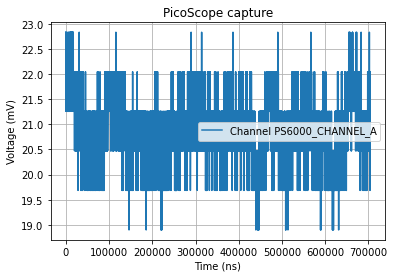

Measured power during trace: 1.37 uW
Max |V| = 22.83 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144800_laserp_23_mW_measp_1.37_uW_iter017_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 23.5000 mW

Iteration 18
Current gain = 70


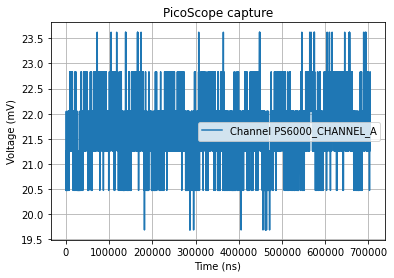

Measured power during trace: 1.37 uW
Max |V| = 23.62 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144809_laserp_23.5_mW_measp_1.37_uW_iter018_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 19
Current gain = 70


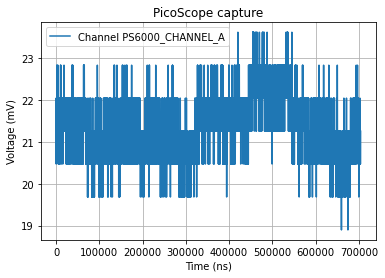

Measured power during trace: 1.37 uW
Max |V| = 23.62 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144822_laserp_23.5_mW_measp_1.37_uW_iter019_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 20
Current gain = 70


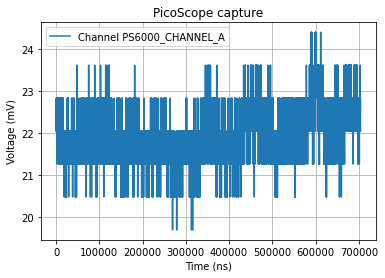

Measured power during trace: 1.37 uW
Max |V| = 24.41 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144833_laserp_23.5_mW_measp_1.37_uW_iter020_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 24.0000 mW

Iteration 21
Current gain = 70


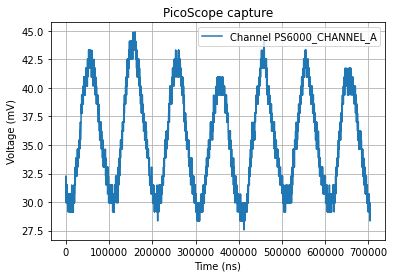

Measured power during trace: 1.38 uW
Max |V| = 44.88 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144845_laserp_24_mW_measp_1.38_uW_iter021_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 22
Current gain = 70


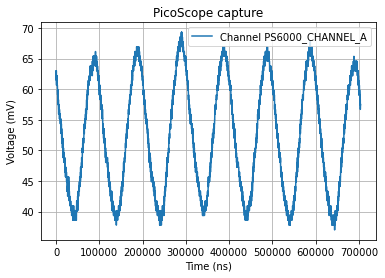

Measured power during trace: 1.39 uW
Max |V| = 69.29 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144852_laserp_24_mW_measp_1.39_uW_iter022_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 23
Current gain = 70


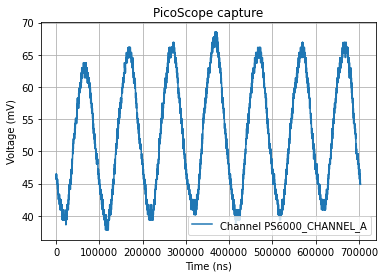

Measured power during trace: 1.41 uW
Max |V| = 68.50 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144906_laserp_24_mW_measp_1.41_uW_iter023_gain_70_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 24.5000 mW

Iteration 24
Current gain = 70


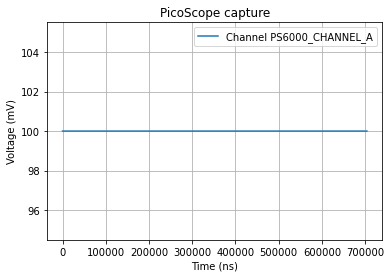


Signal exceeded ±90 mV (max |V| = 100.00 mV).
Please change gain.
Reacquiring iteration 24 with gain = 60

Iteration 24
Current gain = 60


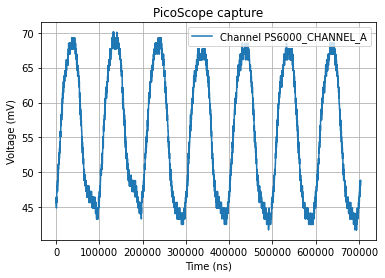

Measured power during trace: 1.52 uW
Max |V| = 70.08 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144932_laserp_24.5_mW_measp_1.52_uW_iter024_gain_60_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 25
Current gain = 60


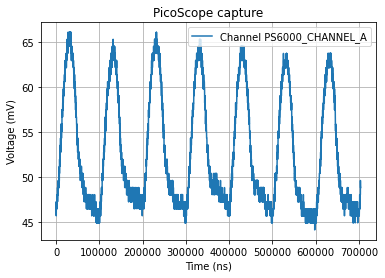

Measured power during trace: 1.49 uW
Max |V| = 66.14 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144946_laserp_24.5_mW_measp_1.49_uW_iter025_gain_60_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 26
Current gain = 60


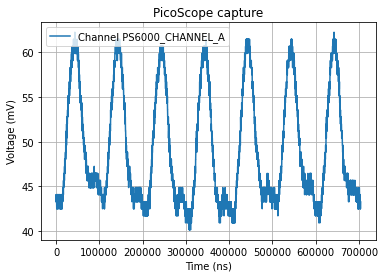

Measured power during trace: 1.48 uW
Max |V| = 62.20 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_144956_laserp_24.5_mW_measp_1.48_uW_iter026_gain_60_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 25.0000 mW

Iteration 27
Current gain = 60


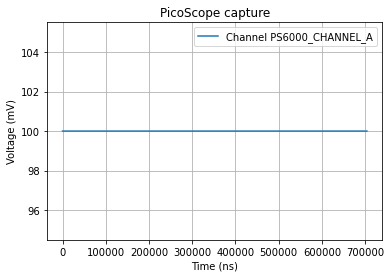


Signal exceeded ±90 mV (max |V| = 100.00 mV).
Please change gain.
Reacquiring iteration 27 with gain = 50

Iteration 27
Current gain = 50


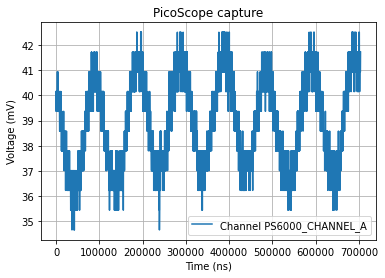

Measured power during trace: 1.65 uW
Max |V| = 42.52 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145100_laserp_25_mW_measp_1.65_uW_iter027_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 28
Current gain = 50


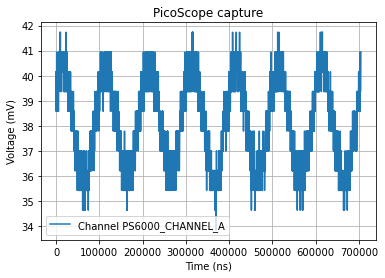

Measured power during trace: 1.67 uW
Max |V| = 41.73 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145111_laserp_25_mW_measp_1.67_uW_iter028_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 29
Current gain = 50


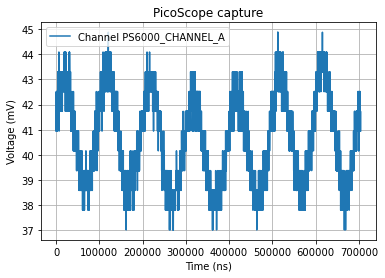

Measured power during trace: 1.67 uW
Max |V| = 44.88 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145122_laserp_25_mW_measp_1.67_uW_iter029_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 25.5000 mW

Iteration 30
Current gain = 50


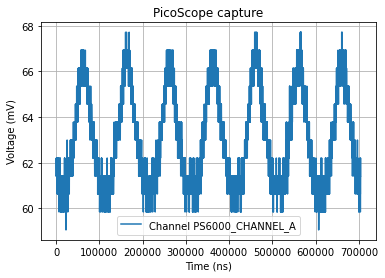

Measured power during trace: 1.88 uW
Max |V| = 67.72 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145134_laserp_25.5_mW_measp_1.88_uW_iter030_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 31
Current gain = 50


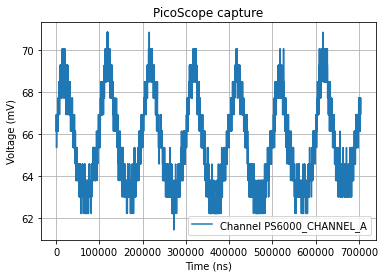

Measured power during trace: 1.89 uW
Max |V| = 70.87 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145144_laserp_25.5_mW_measp_1.89_uW_iter031_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 32
Current gain = 50


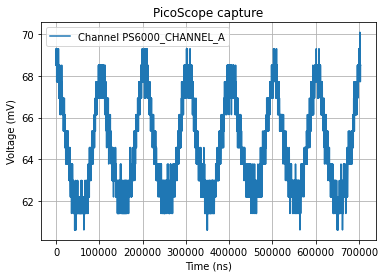

Measured power during trace: 1.89 uW
Max |V| = 70.08 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145152_laserp_25.5_mW_measp_1.89_uW_iter032_gain_50_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 26.0000 mW

Iteration 33
Current gain = 50


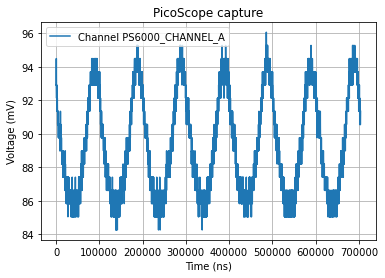


Signal exceeded ±90 mV (max |V| = 96.06 mV).
Please change gain.
Reacquiring iteration 33 with gain = 40

Iteration 33
Current gain = 40


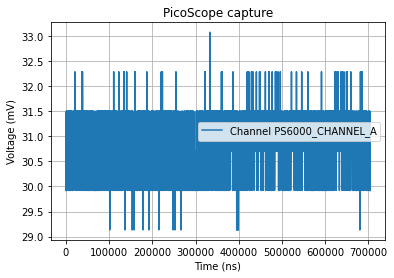

Measured power during trace: 2.11 uW
Max |V| = 33.07 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145241_laserp_26_mW_measp_2.11_uW_iter033_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 34
Current gain = 40


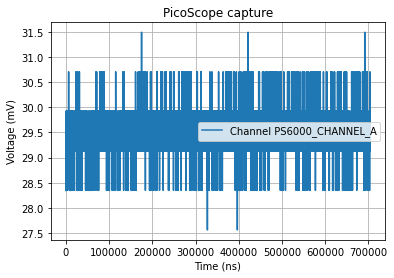

Measured power during trace: 2.08 uW
Max |V| = 31.50 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145254_laserp_26_mW_measp_2.08_uW_iter034_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 35
Current gain = 40


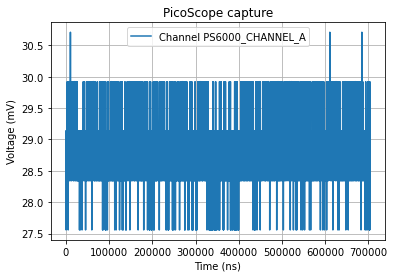

Measured power during trace: 2.04 uW
Max |V| = 30.71 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145305_laserp_26_mW_measp_2.04_uW_iter035_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 26.5000 mW

Iteration 36
Current gain = 40


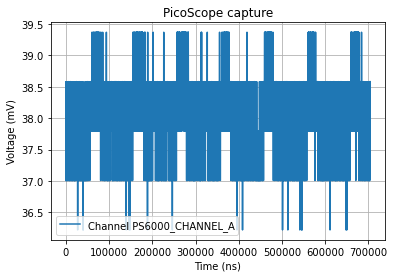

Measured power during trace: 2.33 uW
Max |V| = 39.37 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145317_laserp_26.5_mW_measp_2.33_uW_iter036_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 37
Current gain = 40


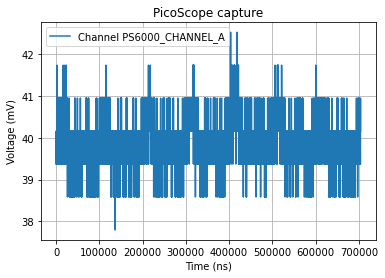

Measured power during trace: 2.32 uW
Max |V| = 42.52 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145328_laserp_26.5_mW_measp_2.32_uW_iter037_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 38
Current gain = 40


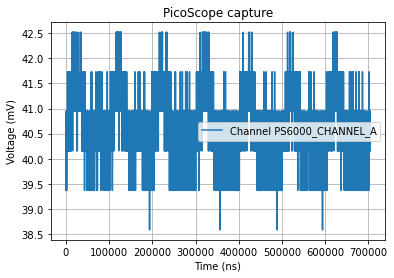

Measured power during trace: 2.38 uW
Max |V| = 42.52 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145338_laserp_26.5_mW_measp_2.38_uW_iter038_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 27.0000 mW

Iteration 39
Current gain = 40


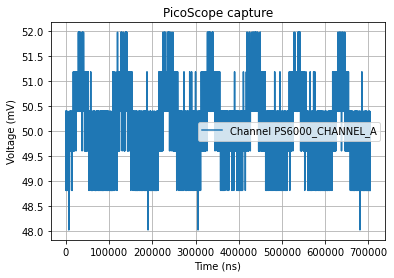

Measured power during trace: 2.64 uW
Max |V| = 51.97 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145350_laserp_27_mW_measp_2.64_uW_iter039_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 40
Current gain = 40


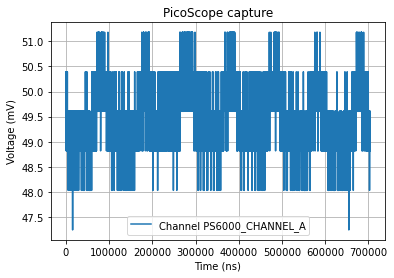

Measured power during trace: 2.63 uW
Max |V| = 51.18 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145401_laserp_27_mW_measp_2.63_uW_iter040_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 41
Current gain = 40


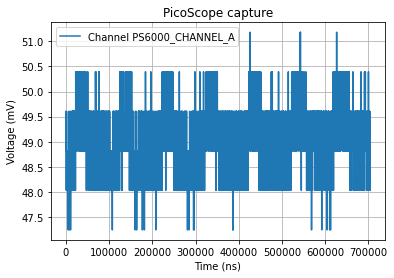

Measured power during trace: 2.62 uW
Max |V| = 51.18 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145411_laserp_27_mW_measp_2.62_uW_iter041_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Setting laser to 27.5000 mW

Iteration 42
Current gain = 40


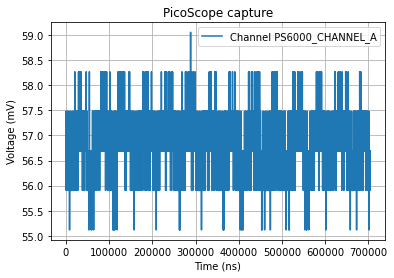

Measured power during trace: 2.85 uW
Max |V| = 59.06 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145423_laserp_27.5_mW_measp_2.85_uW_iter042_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 43
Current gain = 40


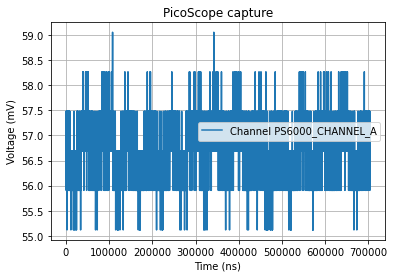

Measured power during trace: 2.86 uW
Max |V| = 59.06 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145434_laserp_27.5_mW_measp_2.86_uW_iter043_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Iteration 44
Current gain = 40


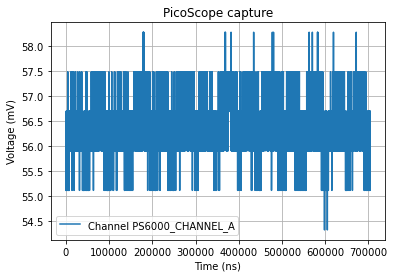

Measured power during trace: 2.84 uW
Max |V| = 58.27 mV
Saved voltage:
D:/Data\2026\202606\20260623\pbec_145445_laserp_27.5_mW_measp_2.84_uW_iter044_gain_40_Voltage.txt
Time file:
D:/Data\2026\202606\20260623\pbec_Time.txt

Power scan complete.


In [4]:

# ---------------------------------------------------------------------
# Example use
# ---------------------------------------------------------------------

power_list = np.append([0], np.arange(21, 28, 0.5) / 1000)
n_iter = 3
# Units are W here.
# 0.001 W = 1 mW
# 0.010 W = 10 mW

scope_settings = dict(
    channels=[0],
    analogue_offset=0,
    trig=0,
    trigsource=0,
    trigthresh=64,
    trigdir=2,
    trigdelay=0,
    trigms=1000,

    preTriggerSamples=0,
    postTriggerSamples=10000,

    timebase=15,

    live_plot=True
)

log_file = run_power_scan(
    power_list=power_list,
    n_iterations=n_iter,
    laser=laser,
    powermeter=powermeter,
    base_directory='D:/Data',
    settle_time_s=1.0,
    power_meter_dt=0.02,
    channel_to_save=0,
    voltage_threshold_mV=90,
    initial_gain_value='70',
    scope_kwargs=scope_settings
)